In [1]:
import os, glob
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

In [2]:
pth = os.path.join('..', '..')
pth_res = os.path.join(pth, 'data', 'results', 'emtarget')
pth_iedb = os.path.join(pth_res, 'IEDB')
pth_fig = os.path.join(pth, 'figures', 'emtarget')

In [3]:
# load co-target nomination results
fn = os.path.join(pth_res, 'nominate.csv')
df = pd.read_csv(fn, index_col = [0, 1])
ix = np.vstack(df.index.values)

In [4]:
# load IEDB results
res_fn = sorted(glob.glob(os.path.join(pth_iedb, '*.csv')))
get_name = lambda fn: os.path.split(fn)[1].replace('.csv', '')
res_dict = {get_name(fn) : pd.read_csv(fn) for fn in res_fn}
df_iedb = pd.concat(res_dict, join = 'inner', axis = 0)
df_iedb = df_iedb.reset_index(names = ['Gene Name', 'index'])
df_iedb['Peptide'] = (df_iedb['Epitope - Name'].str
    .split(' + ', regex = False).str[0].str.strip())

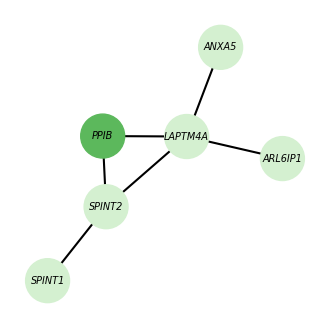

In [5]:
thresh_corr = .1
msk = np.any(ix == 'GPC3', axis = 1)
thresh_expr = df.loc[msk].Expression.min()
msk_expr = (df.Expression < thresh_expr)
msk_corr = (df.Correlation > thresh_corr)
msk_tgt = (msk_expr & msk_corr)

# construct co-target graph
edges = df.index[msk_tgt].values
G_tgt = nx.from_edgelist(edges,
        create_using = nx.Graph)

# plot coexpression network
fig, ax = plt.subplots(1, 1, figsize = (4, 4))
pos = nx.spring_layout(G_tgt, seed = 1)
c = ['#d4f0d0' if node != 'PPIB' else '#5cb85c'
     for node in list(G_tgt.nodes)]
nx.draw_networkx_nodes(
    G_tgt, pos, ax = ax,
    node_color = c,
    node_size = 1000)
lbl = nx.draw_networkx_labels(
    G_tgt, pos, ax = ax,
    font_size = 7)
for t in lbl.values():
    t.set_fontstyle('italic')
nx.draw_networkx_edges(
    G_tgt, pos, ax = ax,
    width = 1.5)
ax.axis('off'); ax.margins(.1)
fn = os.path.join(pth_fig, 'prioritize.pdf')
plt.savefig(fn, bbox_inches = 'tight')

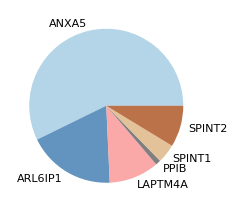

In [6]:
# plot unique epitopes
df_plt = df_iedb.groupby('Gene Name').Peptide.nunique()
ax = df_plt.plot(kind = 'pie', cmap = 'Paired',
                 fontsize = 8, figsize = (2.5, 2.5),
                 wedgeprops = {'alpha': .85})

for i, c in ((1, 'steelblue'),
             (3, 'dimgray'),
             (4, 'burlywood')):
    ax.patches[i].set_facecolor(c)
    ax.patches[i].set_alpha(.85)

ax.set_ylabel('')
fn = os.path.join(pth_fig, 'epitopes.pdf')
plt.savefig(fn, bbox_inches = 'tight')

In [7]:
df_plt.sum()

np.int64(276)